# Replication File IKC

### This is the file replicating Part III:  quantitative environment (sections 6 and 7) from 'The Intertemporal Keynesian Cross'

It includes both a transfer-payment style negative tax shock with possibility of deficit financing through dB and an implementation of means-testing, based on stoachastic realisation of deterministic income.
1:1 replication and proportional transfer payments (through a negative tax shock) possible.
The HA-mt model is one with transfer payments, while this file still offers the possibility of utilizing the fiscal environment of the ikc, making a 

I mainly work with the HANK-models, as all the analytical models are less of interest to me. A HA-one with more realistic MPCs sadly is not working with a GE environment. 

In [37]:
import numpy as np
from scipy import optimize
import json
import matplotlib.pyplot as plt

In [38]:
import sequence_jacobian as sj  
from base import calibration, fiscal, winding_number, capital_sticky_prices
from models import models_analytical, models_heterogeneous
from plotting import sec67_plots as plots

opts = {'texfig': True, 'savefig': True}

In [14]:
#checking mpcs:
for m in ['HA-hi-liq', 'HA-two']:
       J = hh_all[m].partial_jacobians(ss_all[m], inputs=['Z'], outputs=['C'], T=50)
       print(m, np.asarray(J[find_het_block_name(hh_all[m])]['C', 'Z'])[:4, 0])
print(impc_data[:4])

NameError: name 'hh_all' is not defined

In [174]:
#n_e=11
#N_TEST=11
#mt = np.zeros(n_e)
#mt[:N_TEST] = 1.0

In [54]:
e_grid, pi_e, Pi = sj.grids.markov_rouwenhorst(0.91, 0.935348, 11) #US income calibration

In [51]:
e_grid, pi_e, Pi = sj.grids.markov_rouwenhorst(0.81, 0.535348, 11) #Swedish calibration

In [52]:
pi_e

array([0.00097656, 0.00976563, 0.04394531, 0.1171875 , 0.20507812,
       0.24609375, 0.20507812, 0.1171875 , 0.04394531, 0.00976563,
       0.00097656])

In [64]:
0.15952758 + 0.2238107 + 0.31399731 + 0.44052545 + 0.61803929 + 0.86708398 + 1.21648355

3.83946786

In [63]:
0.03374124 +  0.06096419 +  0.11015106 +  0.19902267 +  0.35959729 +0.64972602 +  1.17393518

2.58713765

In [55]:
e_grid

array([ 0.03374124,  0.06096419,  0.11015106,  0.19902267,  0.35959729,
        0.64972602,  1.17393518,  2.12108453,  3.83240883,  6.92445647,
       12.51121669])

In [63]:
ss.internals['hh']['D'].sum(axis=1)

array([0.00097656, 0.00976562, 0.04394531, 0.1171875 , 0.20507812,
       0.24609375, 0.20507812, 0.1171875 , 0.04394531, 0.00976562,
       0.00097656])

In [69]:
pi_e # 0.377:5, 0.623:6, 0.828:7

array([0.00097656, 0.00976563, 0.04394531, 0.1171875 , 0.20507812,
       0.24609375, 0.20507812, 0.1171875 , 0.04394531, 0.00976563,
       0.00097656])

In [48]:
0.00097656 + 0.00976563 + 0.04394531 + 0.1171875 + 0.20507812 + 0.24609375+0.20507812  +0.1171875

0.9453124900000001

In [62]:
mt = np.zeros(11)
mt[:8] = 1.0
mt / (pi_e @ mt) 

array([1.05785124, 1.05785124, 1.05785124, 1.05785124, 1.05785124,
       1.05785124, 1.05785124, 1.05785124, 0.        , 0.        ,
       0.        ])

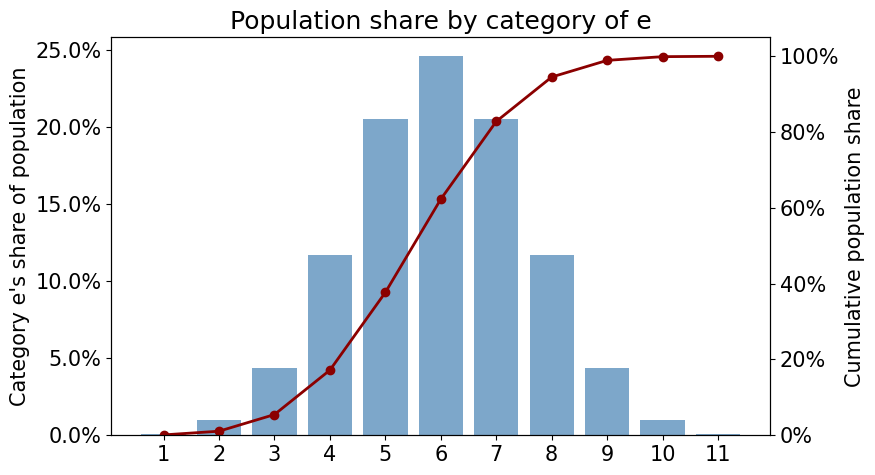

In [11]:
# Estimate mean and standard deviation
#does not change with swedish persistence and sd. 
from matplotlib.ticker import PercentFormatter
categories = [1,2,3,4,5,6,7,8,9,10,11]

cumulative = np.cumsum(pi_e)

fig, ax1 = plt.subplots(figsize=(9, 5))

# Bars = individual category shares
ax1.bar(categories, pi_e, color="steelblue", alpha=0.7)
ax1.set_ylabel("Category e's share of population")
ax1.yaxis.set_major_formatter(PercentFormatter(1))

# Line = cumulative population share
ax2 = ax1.twinx()
ax2.plot(
    categories,
    cumulative,
    color="darkred",
    marker="o",
    linewidth=2
)
ax2.set_ylabel("Cumulative population share")
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_ylim(0, 1.05)
ax2.set_xticks([1,2,3,4,5,6,7,8,9,10,11])

plt.title("Population share by category of e")
plt.tight_layout()
plt.show()

In [37]:
fig.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/Households.png",
    bbox_inches="tight"
)

First, we define simple blocks that characterize fiscal and monetary policy, along with wage inflation and ex-post returns:

In [3]:
@sj.simple
def fiscalrule(B, r, T, w, N):
    #T = (1 + r(-1)) * B(-1) + G - B # fiscal rule from ikc, changed to allow for negative tax shock of an earlier, proportional version of transfer shock. 
    G = -(1+r(-1)) * B(-1) + T + B  #This block defines steady state T.
    #G = -(1+r(-1)) * B(-1) + (tax * np.sum(e_pdf * e_grid) / e_grid) + B 
    Z = w * N - T 
    deficit = B - T + G
    return G, Z, deficit

@sj.simple
def fiscalrule_mt(B, r, T, w, N, Tr):
    #T = (1 + r(-1)) * B(-1) + G - B # taxes
    G = -(1+r(-1)) * B(-1) + T + B - Tr  #This block defines steady state T.
    #G = -(1+r(-1)) * B(-1) + (tax * np.sum(e_pdf * e_grid) / e_grid) + B 
    Z = w*N -T 
    deficit = G + Tr - T #primary deficit
    return G, Z, deficit

@sj.simple
def wage_inflation(pi, w):
    piw = (1 + pi) * w / w(-1) - 1   #This is very close to 0. 
    return piw

@sj.simple
def union(piw, N, UCE, Z, kappaw, vphi, frisch, muw, beta):
    wnkpc = (kappaw * (muw * vphi * N ** (1 / frisch)/(UCE* (1-theta)* Z/N) - 1) + 
             beta * piw(+1)*(1 + piw(+1)) - piw*(1 + piw))
    return wnkpc

@sj.simple
def taylor(r, pi, phi_pi):
    i = r.ss + phi_pi * pi
    return i

@sj.simple
def share_bond(B, J_end_period):
    bondshare = B / ( B + J_end_period)
    return bondshare

@sj.simple
def finance(r, J, J_end_period, bondshare, i, pi):
    rpost = bondshare(-1) * (1+r(-1)) + (1 - bondshare(-1)) * J/J_end_period(-1) - 1   #page 49 of ssj
    fisher = 1 + i - (1 + r) * (1 + pi(+1))
    return rpost, fisher

@sj.simple
def mkt_clearing(A, B, J_end_period, C, I, G, p_adjust, k_adjust, Y):
    asset_mkt = A - B - J_end_period
    goods_mkt = C + I + G + p_adjust + k_adjust - Y 
    return asset_mkt, goods_mkt

Next, we add a block that characterizes production and pricesetting to make the complete list of non-household blocks:


The "other_blocks" specification was left in as a way to bypass some recoding and as a possibility to also do proportional transfer-payments (via a negative tax shock, the incidence of which would not be flat), which did not end up being the in the thesis

In [4]:
other_blocks = [fiscalrule, wage_inflation, union, taylor, 
                capital_sticky_prices.production_pricesetting, share_bond, finance, mkt_clearing]

In [5]:
means = [fiscalrule_mt, wage_inflation, union, taylor, 
                capital_sticky_prices.production_pricesetting, share_bond, finance, mkt_clearing]

# Calibration from main_sec34; 
#### Optional as solved_params already comes with the replication .json file. Necessary, if calibrating with anything else than a total replication of the ikc.

## Hi-liq (A/Z target)


In [6]:
calib = calibration.get_calibration_ikc()                       # general IKC parameters
calib_ha_one, calib_ha_two, calib_ha_mt = calibration.get_ha_calibrations()  # HA-specific parameters

In [7]:
params, hh_het, ss_het = {}, {}, {}

In [8]:
def get_ss_impc_one(beta, Z):
    ss = models_heterogeneous.ha_one.steady_state({**calib, **calib_ha_one, 'beta': beta, 'Z': Z})
    impc = models_heterogeneous.ha_one.impulse_linear(ss, inputs={'Z': 1.*(np.arange(5)==0)})['C']
    return ss, impc

In [9]:
#print(models_heterogeneous.ha_one_uce.hetinputs)

In [10]:
beta = optimize.brentq(lambda beta: get_ss_impc_one(beta, calib['Z'])[0]['A'] - calib['B'], 0.3, 0.95) # 0.94 for low wealth, 0.95 for high
ss, impc = get_ss_impc_one(beta, calib['Z'])
beta, ss['A']/ss['Z'], impc[0]

params['HA-hi-liq'], hh_het['HA-hi-liq'], ss_het['HA-hi-liq'] = {'beta': beta, 'Z': calib['Z']}, models_heterogeneous.ha_one, ss
print(params['HA-hi-liq']['beta'])
#0.942

0.9423072542705814


## HA_TWO

In [11]:
import pandas as pd
df = pd.read_csv('C:/Users/herr-/Documents/Master ECO/Thesis/new IKC replication from github/ikc-main/data/FIG2_c1R_inc_weight.csv', header=None)
impc_data = df[0].values[4:]   # rows 0-3 are pre-periods, impcs start at 4
impc_sd = df[1].values[4:]
#impc_lb_italy = np.loadtxt('intermediates/impc_lb_italy.txt')

In [12]:
def get_ss_impc_two(beta, nu):
    ss = models_heterogeneous.ha_two.steady_state({**calib, **calib_ha_two, 'beta': beta, 'nu': nu})
    impc = models_heterogeneous.ha_two.impulse_linear(ss, inputs={'Z': 1.*(np.arange(5)==0)})['C']
    return ss, impc

In [13]:
def resid_ha_two(x):
    """Solve for beta and nu that match impc and A = B"""
    beta, nu = x
    ss, impc = get_ss_impc_two(beta, nu)
    return np.array([impc[0] - impc_data[0], ss['A'] - calib['B']])

In [14]:
for beta_try in [0.93, 0.931]: #931777086 hits high wealth exactly for the swedisch persistence but not enough to discount r
       ss, impc = get_ss_impc_two(beta_try, 0.089)
       print(beta_try, ss['A'])

0.93 2.160208860296054
0.931 3.1182363922420215


In [15]:
beta0, nu = optimize.fsolve(resid_ha_two, [0.9315, 0.0873]) #0.9315, 0.0872 for low wealth, 0.9309 and 0.088 for high
# extra run to hit asset market clearing exactly
beta = optimize.brentq(lambda beta: get_ss_impc_two(beta, nu)[0]['A'] - calib['B'], beta0-1E-8, beta0+1E-8)
#on low wealth, and a heathcote of 0.4181 calibration with swedisch income persisence is possible but produces a higher gini for hank-two (0.9315366254396349, 0.08728422198681118)

In [16]:
ss, impc = get_ss_impc_two(beta, nu)
beta, nu, ss['A']/ss['Z'], impc[0]


#high wealth: (0.9309403550223855,0.08799417373328512
#low wealth:
#swedish:0.931538867951424, 0.08715863475452602

(0.9309404092380009, 0.0879503982232357, 8.765805071135379, 0.5111663350096846)

In [17]:
params['HA-two'], hh_het['HA-two'], ss_het['HA-two'] = {'beta': beta, 'nu': nu, 'Z': calib['Z']}, models_heterogeneous.ha_two, ss

## HA-mt or model with possibility of means testing

As Tr is 0 in steady state, this should return the same solved parameters. However, we now have 2 models with different fiscal blocks. 

In [18]:
def get_ss_impc_mt(beta, nu):
    ss = models_heterogeneous.ha_mt.steady_state({**calib, **calib_ha_mt, 'beta': beta, 'nu': nu})
    impc = models_heterogeneous.ha_mt.impulse_linear(ss, inputs={'Z': 1.*(np.arange(5)==0)})['C']
    return ss, impc

In [19]:
def resid_ha_mt(x):
    """Solve for beta and nu that match impc and A = B"""
    beta, nu = x
    ss, impc = get_ss_impc_mt(beta, nu)
    return np.array([impc[0] - impc_data[0], ss['A'] - calib['B']])

In [20]:
beta0, nu = optimize.fsolve(resid_ha_mt, [0.9315, 0.0872]) #0.9315, 0.0872 for low wealth, 0.9309 and 0.088 for high
# extra run to hit asset market clearing exactly
beta = optimize.brentq(lambda beta: get_ss_impc_mt(beta, nu)[0]['A'] - calib['B'], beta0-1E-8, beta0+1E-8)
#on low wealth, and a heathcote of 0.4181 calibration with swedisch income persisence is possible but produces a higher gini for hank-two (0.9315366254396349, 0.08728422198681118)

In [21]:
ss, impc = get_ss_impc_mt(beta, nu)
beta, nu, ss['A']/ss['Z'], impc[0]

#Archive of past solved calibrations:
#11 and hi wealth: 0.931 and 0.0879
#swedish persistance: 0.931 and 0.0872
#11 and low: 0.9309 and 0.0890

(0.9309404092415423,
 0.08795039822882926,
 8.765805071135226,
 0.5111663349967582)

In [22]:
params['HA-mt'], hh_het['HA-mt'], ss_het['HA-mt'] = {'beta': beta, 'nu': nu, 'Z': calib['Z']}, models_heterogeneous.ha_mt, ss

### HA-one (MPC target)

This does not produce a steady state in the full quantitative environment

In [23]:
Y, G, r = calib['Y'], calib['G'], calib['r']
def resid_ha_one(x):
    """Solve for beta and Z that match impc and Y = r*A + G + Z"""
    beta, Z = x
    ss, impc = get_ss_impc_one(beta, Z)
    return np.array([impc[0] - impc_data[0], Y - r*ss['A'] - G - Z])

beta, Z_ha_one = optimize.fsolve(resid_ha_one, [0.93, calib['Z']])
ss, impc = get_ss_impc_one(beta, Z_ha_one)
beta, ss['A']/ss['Z'], impc[0]
params['HA-one'], hh_het['HA-one'], ss_het['HA-one'] = {'beta': beta, 'Z': Z_ha_one}, models_heterogeneous.ha_one, ss
print(params['HA-one']['beta'])

#swedish persistance: 0.8696
#lowwealth 0.8656

0.8657595779081287


In [24]:
#maximum discount factor value
#1/(1+ss['r'])

# End of the optional part

## Setup: Calibration of the household blocks

In [25]:
#only run this if you want to change the solved parameter file
with open('solved_params.json', 'w') as json_file:
    json.dump(params, json_file, indent=4)

In [26]:
with open('solved_params.json', 'r') as json_file:
    params = json.load(json_file)

In [27]:
hh_het, ss_het = models_heterogeneous.get_all_quant(params)
hh_all = {**hh_het}
ss_all = {**ss_het}
hh_names = {m: hh_all[m].name for m in hh_all}

In [8]:
#hh_all['HA-hi-liq'].hetinputs
#hh_all['HA-hi-liq'].internals

Now we'll back out what the vphi in preferences needs to be by inverting the equation for zero wage inflation in steady state:

In [28]:
calib = calibration.get_calibration_quant()
muw, N, frisch, theta, Z = [calib[k] for k in ('muw', 'N', 'frisch', 'theta', 'Z')]
vphi_base = (1-theta)* Z/N**(1+1/frisch)/muw  # cutting (1-theta)*Z halfs the wknpc
for m in ss_all:
    ss_all[m]['vphi'] = vphi_base*ss_all[m]['UCE']   #A.168

In [29]:
print( [calib[k] for k in ('muw', 'N', 'frisch', 'theta', 'Z', 'A')])
print(ss_all['HA-mt']['vphi'])

[1.001, 1, 1, 0.181, 0.47099929400070595, 4.128688]
0.77441462096192


## Setup: obtain steady states for all models
This involves a little bit of unnecessary redundancy since it's evaluating the household steady states again:

In [30]:
extra_blocks = {
    'HA-mt': means,   # uses means for every model listed, change this to HA-hi-liq to evaluate the one-account one with transfers.
}

models_all = {
    m: sj.combine([*extra_blocks.get(m, other_blocks), hh_all[m]])
    for m in hh_all
}
for m in models_all:
    ss_all[m] = models_all[m].steady_state({**ss_all[m], **calib})

In [11]:
#ss_all['HA-hi-liq'].toplevel

In [12]:
#does not work with Tr because it is only included in the HANK-two.
models_all = {m: sj.combine([*other_blocks, hh_all[m]]) for m in hh_all
for m in models_all:
        ss_all[m] = models_all[m].steady_state({**ss_all[m], **calib})

SyntaxError: '{' was never closed (1712132460.py, line 2)

In [31]:
ha_mt=sj.combine([*means, hh_all['HA-mt']])
ss_mt=ha_mt.steady_state({**ss_all['HA-mt'], **calib })

In [11]:
ha=sj.combine([*means, hh_all['HA-hi-liq']])
ss=ha.steady_state({**ss_all['HA-hi-liq'], **calib })

In [13]:
#ha_two=sj.combine([*other_blocks, hh_all['HA-two']])
#ss_two=ha_two.steady_state({**ss_all['HA-two'], **calib })
#ikc version without transfers

In [36]:
ss_mt.toplevel

{'B': 1.8671318000177393,
 'r': 0.05,
 'T': 0.2350000000000001,
 'w': 0.705999294000706,
 'Tr': 0.0,
 'kappaw': 0.030888627273340998,
 'vphi': 0.77441462096192,
 'frisch': 1,
 'muw': 1.001,
 'beta': 0.9309404092415423,
 'phi_pi': 1.5,
 'Y': 1.0,
 'Theta': 0.7866931309456923,
 'alpha': 0.294,
 'delta': 0.08,
 'epsI': 4,
 'kappap': 0.23203463203463207,
 'mup': 1.000001,
 'eis': 1,
 'rho_e': 0.91,
 'sd_e': 0.75348,
 'n_e': 11,
 'min_a': 0.0,
 'max_a': 10000,
 'n_a': 50,
 'min_b': 0.0,
 'max_b': 10000,
 'n_b': 50,
 'nu': 0.08795039822882926,
 'zeta': 0.07619047619047618,
 'Q': 1.0,
 'K': 2.261536200002198,
 'N': 1.0000000000000115,
 'mc': 0.9999990000010117,
 'inv': 0.0,
 'val': 5.10702591327572e-15,
 'pi': -4.437379308024466e-13,
 'nkpc': 2.380952364360091e-14,
 'p_adjust': 4.242973333817835e-19,
 'k_adjust': 0.0,
 'I': 0.18092289600017564,
 'div': 0.11307780999911021,
 'J': 2.3746340099813086,
 'valJ': 0.0,
 'J_end_period': 2.2615561999821985,
 'bondshare': 0.45223368780052337,
 'i': 0.0

# some sanity cheks of the A/Z calibrations and ss, which to just get to the results are not necessary

In [12]:
A=np.vdot(ss.internals['hh']['a'], ss.internals['hh']['D'])
print(A)

2.591020000000045


In [33]:
ss['A']

2.591020000000045

In [35]:
(0.7+2.2615362000022614+1.99999799987971e-05)*(1/0.706)
#this is how we get to the necessary 4.2. SO if we divide our values by the last term we at least get the correct A.

4.230794571403229

In [18]:
print(A/0.4709992940007061)

8.618908885230546


In [64]:
print(5.848*0.706, 4.33175*0.706, 4.2*0.706)
#print(5.85*0.706, 3.67*0.706, 4.2*0.706)
#these are the values needed for A + control for the orginal value

4.1286879999999995 3.0582155 2.9652


In [66]:
#put the A from above here to calculate the necessary B_Y
4.1286879999999995   -2.2615362000022614-1.99999799987971e-05 #0.7 is correct (B_Y) #-K_Y-Pi_Y

1.8671318000177393

In [46]:
#ss_all['HA-hi-liq'].toplevel
#T taken from the calibration of unchanged(0.2350000000000001). THis comes from the definition of the fiscalrule block

Test to ensure that all steady-state targets are equal to zero:

In [34]:
for m in models_all:
    for k in ('wnkpc', 'pi', 'piw', 'fisher', 'asset_mkt'):
        assert np.isclose(ss_all['HA-hi-liq'][k], 0)
    assert np.isclose(ss_all['HA-hi-liq']['goods_mkt'], 0, atol=1E-5) # less exact for HA-two

In [12]:
print(f"Asset market clearing: {ss_all['HA-hi-liq']['asset_mkt']: 0.2e}")
print(f"NKPC: {ss_all['HA-hi-liq']['wnkpc']: 0.2e}")
print(f"Goods market clearing (untargeted): {ss_all['HA-hi-liq']['goods_mkt']: 0.2e}")
print(f"Fisher: {ss_all['HA-hi-liq']['fisher']: 0.2e}")

Asset market clearing:  1.53e-13
NKPC:  2.63e-14
Goods market clearing (untargeted):  1.04e-08
Fisher: -2.00e-13


## Jacobians

In [69]:
#original without transfers
T = 500
Js_cache = {m: hh_all[m].partial_jacobians(ss_all[m], inputs=['Z', 'rpost'], outputs=['C', 'A', 'UCE'], T=T) for m in models_all}
#Js = {m: hh_all[m].jacobian(ss_all[m], inputs=['Z', 'rpost'], outputs=['C', 'A'], T=T, Js=Js_cache[m]) for m in models_all}

### MEans testing

In [32]:
T=500
Js_cache_mt = hh_all['HA-mt'].partial_jacobians(ss_all['HA-mt'], inputs=['Z','rpost', 'Tr'], #rpost is capital gains, UCE is virtual consumption
                                              outputs=['C','A','UCE'], T=T) #household policy Jacobians

unknowns = ['Y', 'w', 'r']
targets = ['goods_mkt', 'wnkpc', 'fisher']  #changed it to goods_mkt
inputs = ['B', 'Tr', 'T']    
outputs = ['C', 'I', 'N', 'pi', 'Y', 'r', 'Z', 'G', 'deficit', 'A', 'y', 'rpost', 'piw']

Gs_mt = models_all['HA-mt'].solve_jacobian(ss_all['HA-mt'], unknowns, targets, inputs, outputs, T=T, Js=Js_cache_mt) #GE Jacobians

In [33]:
rhoG = 0.01 #very fast decay
rhoBs = [0.0, 0.75, 0.93] #level of deficit financing

dT = 0.00997 * rhoG ** np.arange(T)   #previously quarterly at 0.0398, annual calibration requires 0.00997.

dpis = {}
for rhoB in rhoBs:
    dB  = fiscal.Bplan(dT, rhoB) #uses Bplan from auxilliary fiscal file
    shock = {'Tr': dT, 'B': dB}
    dpis[rhoB] = Gs_mt @ shock

def multiplier_path(dY, dT, r): #defines an output multiplier as part of the IRFs
    q = (1 + r) ** (-np.arange(len(dY)))
    cum_dY = np.cumsum(q * dY)
    cum_dG = np.cumsum(q * dT) #a slopiness carried over from earlier versions of this code, where dG was labled as a tax shock. In the end, the naming is irrelevant, as the shock is always defined as stemming from a positive change in Tr.
    return cum_dY / cum_dG

mult_paths = {rhoB: multiplier_path(dpis[rhoB]['Y'], dT, calib['r']) for rhoB in rhoBs}

In [34]:
#calculating cumulative multipliers
mult_impact, mult_5Y, mult_cumul = {}, {}, {}
for rhoB in rhoBs:
    dY = dpis[rhoB]['Y']
    mult_impact[rhoB], mult_5Y[rhoB], mult_cumul[rhoB] = fiscal.compute_multipliers(dY, dT, calib['r'])

for rhoB in rhoBs:
    print(f"rhoB={rhoB:.2f}:  impact={mult_impact[rhoB]:.3f}   5Y={mult_5Y[rhoB]:.3f}   cumulative={mult_cumul[rhoB]:.3f}")



#5:
#rhoB=0.00:  impact=-0.323   5Y=-0.577   cumulative=-0.662
#rhoB=0.75:  impact=0.827   5Y=0.087   cumulative=-0.172
#rhoB=0.93:  impact=1.136   5Y=0.745   cumulative=0.524


#6:
#rhoB=0.00:  impact=-0.321   5Y=-0.484   cumulative=-0.553
#rhoB=0.75:  impact=0.829   5Y=0.181   cumulative=-0.062
#rhoB=0.93:  impact=1.138   5Y=0.839   cumulative=0.633


#7
#rhoB=0.00:  impact=-0.411   5Y=-0.481   cumulative=-0.546
#rhoB=0.75:  impact=0.739   5Y=0.183   cumulative=-0.055
#rhoB=0.93:  impact=1.048   5Y=0.841   cumulative=0.640


#8:
#rhoB=0.00:  impact=-0.501   5Y=-0.516   cumulative=-0.575
#rhoB=0.75:  impact=0.648   5Y=0.148   cumulative=-0.085
#rhoB=0.93:  impact=0.957   5Y=0.806   cumulative=0.611


#11
#rhoB=0.00:  impact=-0.545   5Y=-0.542   cumulative=-0.595
#rhoB=0.75:  impact=0.604   5Y=0.123   cumulative=-0.104
#rhoB=0.93:  impact=0.913   5Y=0.781   cumulative=0.591



#11, low wealth
#rhoB=0.00:  impact=-0.558   5Y=-0.567   cumulative=-0.605
#rhoB=0.75:  impact=0.627   5Y=0.284   cumulative=0.047
#rhoB=0.93:  impact=0.932   5Y=1.085   cumulative=0.944


#11, low wealth and swedisch:
#rhoB=0.00:  impact=-0.597   5Y=-0.543   cumulative=-0.565
#rhoB=0.75:  impact=0.587   5Y=0.371   cumulative=0.154
#rhoB=0.93:  impact=0.898   5Y=1.203   cumulative=1.117


#11, HANK-one
#rhoB=0.00:  impact=-0.889   5Y=-0.934   cumulative=-1.214
#rhoB=0.75:  impact=-0.194   5Y=-0.732   cumulative=-1.195
#rhoB=0.93:  impact=-0.027   5Y=-0.392   cumulative=-1.064


#7 and low:    
#rhoB=0.00:  impact=-0.420   5Y=-0.475   cumulative=-0.524
#rhoB=0.75:  impact=0.766   5Y=0.376   cumulative=0.128
#rhoB=0.93:  impact=1.071   5Y=1.177   cumulative=1.024
    
    
#7 and swedish:
#rhoB=0.00:  impact=-0.456   5Y=-0.422   cumulative=-0.454
#rhoB=0.75:  impact=0.728   5Y=0.492   cumulative=0.265
#rhoB=0.93:  impact=1.039   5Y=1.324   cumulative=1.229

rhoB=0.00:  impact=-0.545   5Y=-0.541   cumulative=-0.595
rhoB=0.75:  impact=0.603   5Y=0.115   cumulative=-0.112
rhoB=0.93:  impact=0.912   5Y=0.765   cumulative=0.573


In [35]:
#more detailed view for 5 years
for rhoB, dY in dpis.items():
    print(rhoB, dY['Y'][:5])

0.0 [-0.00542939  0.0010161  -0.00071891 -0.0001516  -0.00023998]
0.75 [ 0.00601207 -0.00298361 -0.00051132 -0.00108279 -0.00074794]
0.93 [ 0.00908892 -0.00182558  0.00072129 -0.00025235 -0.00010878]


### Transfer payment part over - Do not run these unless needed

In [46]:
# Proportinal taxes one
T=500
Js_cache_mt = hh_all['HA-mt'].partial_jacobians(ss_all['HA-mt'], inputs=['Z','rpost', 'T'], #deleting the value out of the cache does not do anything.
                                              outputs=['C','A','UCE'], T=T)

unknowns = ['Y', 'w', 'r']
targets = ['goods_mkt', 'wnkpc', 'fisher']  #changed it to goods_mkt
inputs = ['B', 'T']    
outputs = ['C', 'I', 'N', 'pi', 'Y', 'r', 'Z', 'G', 'deficit', 'A', 'y', 'rpost']

Gs = models_all['HA-mt'].solve_jacobian(ss_all['HA-mt'], unknowns, targets, inputs, outputs, T=T, Js=Js_cache_mt)

In [41]:
#Proportional Taxes one
rhoG = 0.01
rhoBs = [0.0, 0.75, 0.93]   # persistence values you want to compare

dT = 0.00997  * rhoG ** np.arange(T)   # same tax shock path for every scenario

dpis = {}
for rhoB in rhoBs:
    dB = fiscal.Bplan(dT, rhoB)
    shock = {'T': dT, 'B': dB}
    dpis[rhoB] = Gs @ shock

In [45]:
list(next(iter(dpis.values())).keys())

['Tr', 'B', 'Y', 'r', 'C', 'I', 'N', 'pi', 'Z', 'G', 'deficit', 'A']

# Plotting multiple rhos

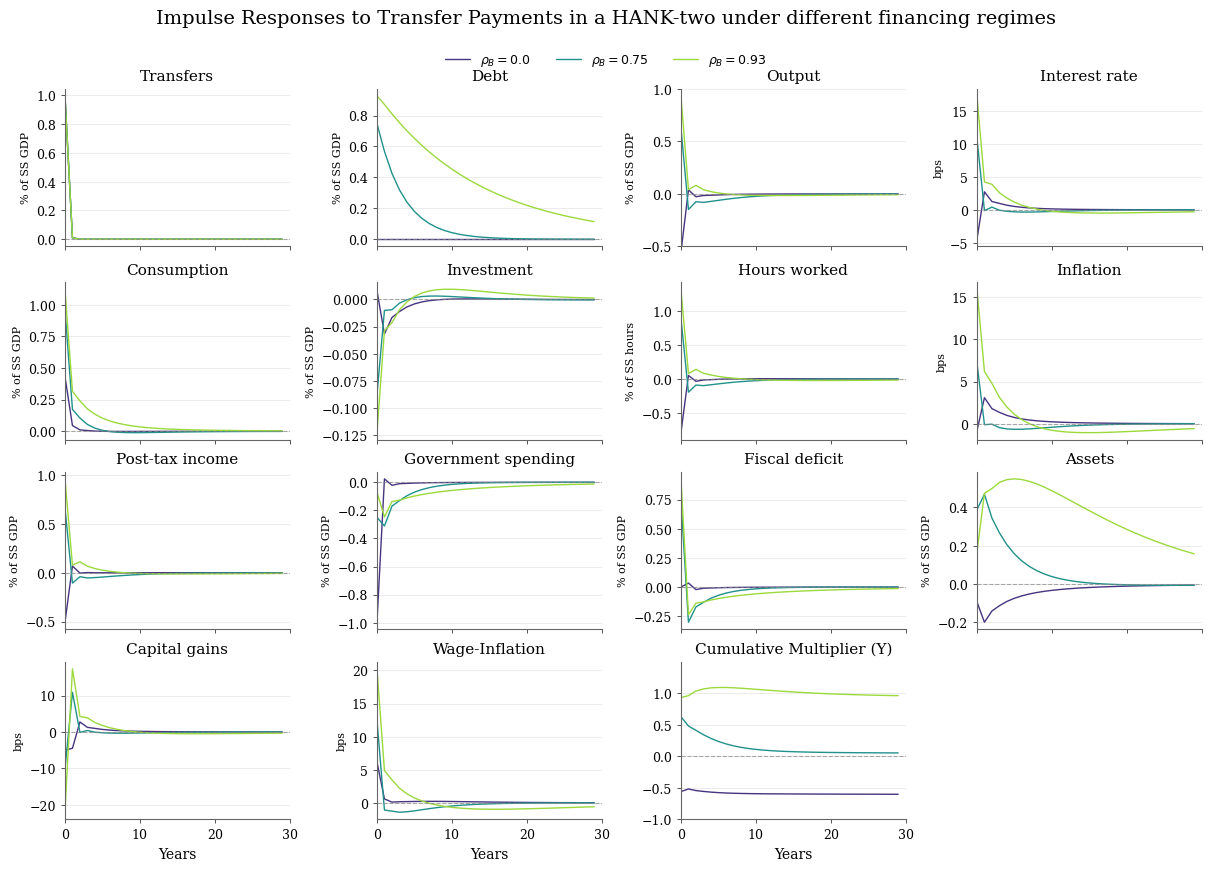

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------

horizon = 30

variables = list(next(iter(dpis.values())).keys())   # ['T', 'B', 'Y', 'r', 'C', 'I', 'N', 'pi', 'Z', 'rpost', 'G', 'deficit', 'A']


rates = {'r', 'pi', 'rpost', 'piw'}

#rescaling rates to be output in basis points and other variables to be output in steady-state deviationsin percent
def rescale(var, path):
    if var in rates: return 1e4 * path                 # basis points
    if var == 'N':   return 100 * path / ss_mt['N']       # % of steady-state hours
    return 100 * path / ss_mt['Y']                        # % of steady-state GDP

units = {v: 'bps' if v in rates else ('% of SS hours' if v == 'N' else '% of SS GDP')
         for v in variables}


# ---------------------------------------------------------
# Cumulative multiplier on output, one path per financing regime
# ---------------------------------------------------------

def multiplier_path(dY, dG, r):
    q = (1 + r) ** (-np.arange(len(dY)))
    cum_dY = np.cumsum(q * dY)
    cum_dG = np.cumsum(q * dG)
    return cum_dY / cum_dG

mult_paths = {rhoB: multiplier_path(dpis[rhoB]['Y'], dT, calib['r']) for rhoB in rhoBs}


irf_color = "#2F6DB0"       # blue
zero_color = "#888888"

plt.rcParams.update({
    "savefig.directory": 'C:/Users/herr-/Documents/Master ECO/Thesis/Results',
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------

ncols = 4
nrows = 4

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

axes = np.asarray(axes).flatten()

# ---------------------------------------------------------
# Plot IRFs
# ---------------------------------------------------------

titles = {
    "Tr": "Transfers",
    "B": "Debt",
    "Y": "Output",
    "r": "Interest rate",
    "C": "Consumption",
    "I": "Investment",
    "N": "Hours worked",
    "rpost" : "Capital gains",
    "pi": "Inflation",
    "piw" : "Wage-Inflation", 
    "Z": "Post-tax income",
    "G": "Government spending",
    "deficit": "Fiscal deficit",
    "A": "Assets",
    "mult_paths": "Cumulative Multiplier (Y)",
}

cmap = plt.cm.viridis
colors = cmap(np.linspace(0.15, 0.85, len(rhoBs)))

for i, var in enumerate(variables):
    ax = axes[i]
    for rhoB, color in zip(rhoBs, colors):
        ax.plot(
            rescale(var, dpis[rhoB][var])[:horizon],
            color=color,
            linewidth=1,
            solid_capstyle="round",
            label=fr"$\rho_B = {rhoB}$"
        )
    ax.axhline(0, color=zero_color, linewidth=0.8, linestyle="--", alpha=0.7)
    ax.set_xlim(0, horizon - 10)
    ax.set_ylabel(units[var], fontsize=8)
    ax.set_xticks([0, 10, 20, 30])
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.6, alpha=0.6)
    ax.tick_params(length=3, width=0.7, color="#555555")
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    if var == 'Y':
        ax.set_ylim(-0.5, 1)
        ax.set_yticks(np.arange(-0.5, 1.5, 0.5))
    ax.set_title(titles[var])




# ---------------------------------------------------------
# Cumulative multiplier panel (uses the one extra slot already
# reserved by the "Remove unused panels" step below)
# ---------------------------------------------------------
ax = axes[len(variables)]
for rhoB, color in zip(rhoBs, colors):
    ax.plot(
        mult_paths[rhoB][:horizon],
        color=color,
        linewidth=1,
        solid_capstyle="round",
        label=fr"$\rho_B = {rhoB}$"
    )
ax.axhline(0, color=zero_color, linewidth=0.8, linestyle="--", alpha=0.7)
ax.set_xlim(0, horizon - 10)
ax.set_xticks([0, 10, 20, 30])
ax.set_yticks([-1,-0.5,0, 0.5, 1])
ax.grid(axis="y", color="#D9D9D9", linewidth=0.6, alpha=0.6)
ax.tick_params(length=3, width=0.7, color="#555555")
ax.spines["left"].set_color("#666666")
ax.spines["bottom"].set_color("#666666")
ax.set_ylim(-1, 1.5) # delete for lower multipliers
ax.set_yticks(np.arange(-1, 1.5, 0.5))
ax.set_title(titles["mult_paths"])

# ---------------------------------------------------------
# Remove unused panels
# ---------------------------------------------------------

for ax in axes[len(variables)+1:]:
    ax.remove()

# ---------------------------------------------------------
# X-axis labels
# ---------------------------------------------------------

# Only labels the bottom row to avoid repetition — now covers the
# multiplier panel too, since it sits in the grid's last row
for i, ax in enumerate(axes[:len(variables)+1]):
    if i // ncols == nrows - 1:
        ax.set_xlabel("Years", labelpad=4)
    else:
        ax.tick_params(labelbottom=False)

# ---------------------------------------------------------
# Figure title
# ---------------------------------------------------------

fig.suptitle(
    "Impulse Responses to Transfer Payments in a HANK-two under different financing regimes",
    fontsize=14,
    fontweight="medium",
    y=1.07
)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=len(rhoBs),
    frameon=False,
    fontsize=9
)

plt.show()

In [19]:
fig.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/11_low.png",
    bbox_inches="tight"
)

# rho_B = 0.93 as check

In [17]:
rhoG = 0.01
rhoB = 0.93 # This can control the degree of deficit-spending

dT = 0.00997 *rhoG**np.arange(T)
dB = fiscal.Bplan(dT, rhoB) 
shock = {'Tr': dT, 'B': dB}
#shock = {'T': dT}

dpi = Gs_mt @ shock

In [40]:
#plt.rcParams.keys()

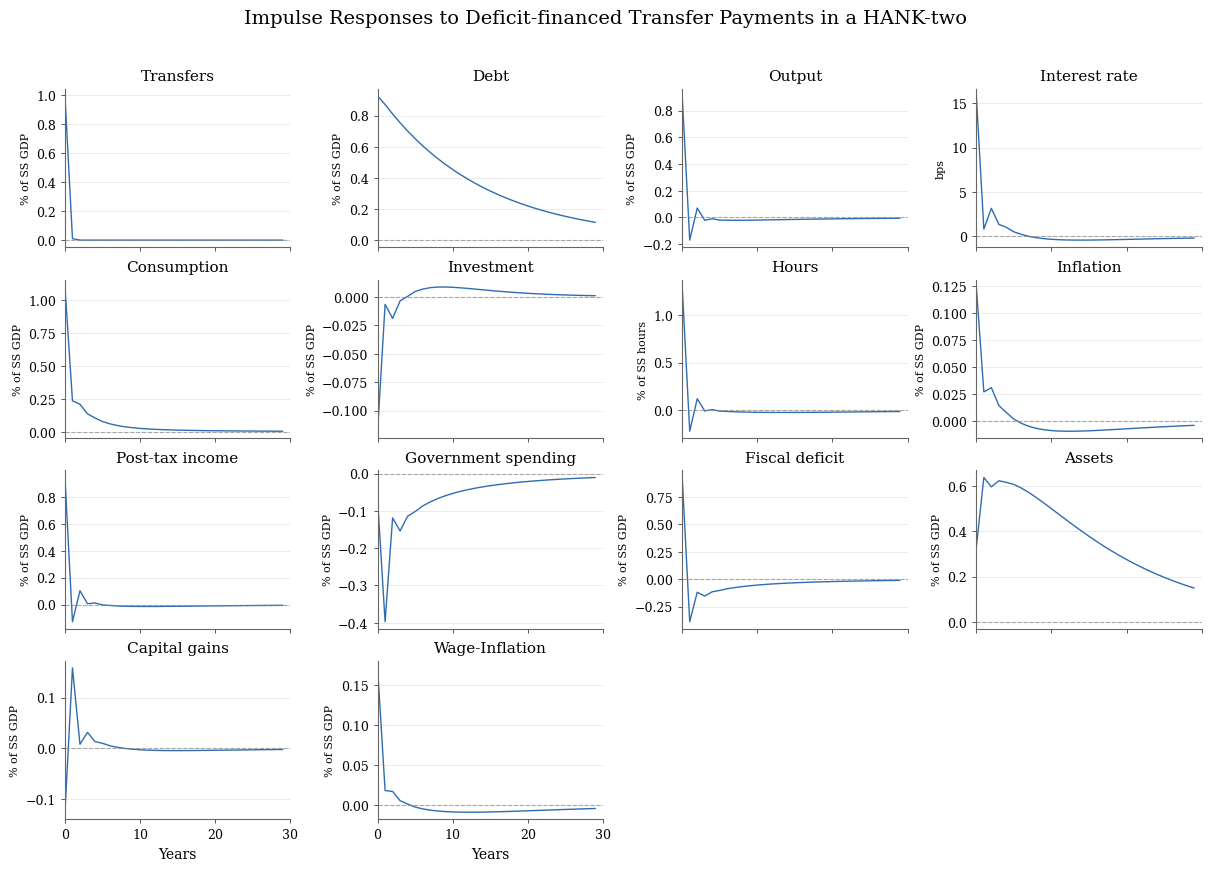

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------

horizon = 30

variables = list(dpi.keys())   # ['T', 'B', 'Y', 'r', 'C', 'I', 'N', 'pi', 'Z', 'rpost', 'G', 'deficit', 'A']


rates = {'r', 'rpost' 'pi'}

def rescale(var, path):
    if var in rates: return 1e4 * path                 # basis points
    if var == 'N':   return 100 * path / ss_mt['N']       # % of steady-state hours
    return 100 * path / ss_mt['Y']                        # % of steady-state GDP

units = {v: 'bps' if v in rates else ('% of SS hours' if v == 'N' else '% of SS GDP')
         for v in variables}


irf_color = "#2F6DB0"       # blue
zero_color = "#888888"

plt.rcParams.update({
    "savefig.directory": 'C:/Users/herr-/Documents/Master ECO/Thesis/Results',
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------

ncols = 4
nrows = 4

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

axes = np.asarray(axes).flatten()

# ---------------------------------------------------------
# Plot IRFs
# ---------------------------------------------------------

titles = {
    "Tr": "Transfers",
    "B": "Debt",
    "Y": "Output",
    "r": "Interest rate",
    "C": "Consumption",
    "I": "Investment",
    "N": "Hours",    
    "rpost" : "Capital gains",
    "pi": "Inflation",
    "piw" : "Wage-Inflation", 
    "Z": "Post-tax income",
    "G": "Government spending",
    "deficit": "Fiscal deficit",
    "A": "Assets",
}

for i, var in enumerate(variables):

    ax = axes[i]

    # IRF
    ax.plot(
        rescale(var, dpi[var][:horizon]),
        color=irf_color,
        linewidth=1,
        solid_capstyle="round"
    )

    # Zero line
    ax.axhline(
        0,
        color=zero_color,
        linewidth=0.8,
        linestyle="--",
        alpha=0.7
    )

    # Title
    ax.set_title(
        var,
        fontsize=11,
        fontweight="medium",
        pad=6
    )

    # X-axis
    ax.set_xlim(0, horizon - 1)
    ax.set_xticks([0, 10, 20, 30])
    ax.set_ylabel(units[var], fontsize=8)
    # Light horizontal grid
    ax.grid(
        axis="y",
        color="#D9D9D9",
        linewidth=0.6,
        alpha=0.6
    )

    # Ticks
    ax.tick_params(
        length=3,
        width=0.7,
        color="#555555"
    )

    # Slightly lighter spines
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.set_title(titles[var])

# ---------------------------------------------------------
# Remove unused panels, without cumulative multiplier panel
# ---------------------------------------------------------

for ax in axes[len(variables):]:
    ax.remove()


# ---------------------------------------------------------
# X-axis labels
# ---------------------------------------------------------

# Only label the bottom row to avoid repetition
for i, ax in enumerate(axes[:len(variables)]):

    if i // ncols == nrows - 1:
        ax.set_xlabel("Years", labelpad=4)
    else:
        ax.tick_params(labelbottom=False)


# ---------------------------------------------------------
# Figure title
# ---------------------------------------------------------

fig.suptitle(
    "Impulse Responses to Deficit-financed Transfer Payments in a HANK-two", 
    fontsize=14,
    fontweight="medium",
    y=1.07
)
#"Impulse Responses to Tax and Deficit Shocks in a high-liquidity HANK-one",
plt.show()

In [22]:
fig.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/Impulse Responses to Transfers, 0.93 in a HANK-two.png",
    bbox_inches="tight"
)

In [172]:
#ss_mt.internals

## Cognitive Discounting

In [20]:
from numba import njit
theta_cd=1 #cd because it would interfere with the progressivity parameter theta 

@njit
def manipulate_separable(M, E):
    """E is the expectations matrix, M is the FIRE (rational) Jacobian"""
    T, m = M.shape
    M_beh = np.empty_like(M)
    for t in range(T):
        for s in range(T):
            summand = 0
            for tau in range(min(s, t) + 1):
                if tau > 0:
                    summand += (E[tau, s] - E[tau-1, s]) * M[t - tau, s - tau]
                else:
                    summand += E[tau, s] * M[t - tau, s - tau]
            M_beh[t, s] = summand
    return M_beh

def E_cog_disc(theta_cd, T):
    E = np.ones((T, T))
    for t in range(T):
        E[t, t:] = theta_cd ** np.arange(T - t)
    return E

In [21]:
from sequence_jacobian.blocks.het_block import HetBlock

E=E_cog_disc(theta_cd, T)
def find_het_block_name(block):
    """Find the .name of the underlying HetBlock, whether `block` is a bare
    HetBlock or a CombinedBlock alongside accounting blocks."""
    if isinstance(block, HetBlock):
        return block.name
    if hasattr(block, 'blocks'):          # CombinedBlock (or any Parent)
        for sub in block.blocks:
            name = find_het_block_name(sub)
            if name is not None:
                return name
    return None

Js_cache_beh = {}
Js_cache_beh['HA-mt'] = dict(Js_cache_mt)          # keep accounting sub-blocks untouched
het_name = find_het_block_name(hh_all['HA-mt'])
J_het = Js_cache_mt[het_name]

beh = {o: {i: manipulate_separable(np.asarray(J_het[o, i]), E)
            for i in J_het.inputs}
        for o in J_het.outputs}
Js_cache_beh['HA-mt'][het_name] = sj.JacobianDict(beh, outputs=J_het.outputs, inputs=J_het.inputs, T=T)

Gs_beh = models_all['HA-mt'].solve_jacobian(ss_all['HA-mt'], unknowns, targets, inputs, outputs,
                                           T=T, Js=Js_cache_beh['HA-mt'])

In [22]:
rhoG = 0.01
rhoB = 0.93 # This can control the degree of deficit-spending

dG = 0.00997 *rhoG**np.arange(T)
dB = fiscal.Bplan(dG, rhoB) 

drp2,drp1 = np.zeros_like(dG), np.zeros_like(dB)
drp2[40:] = dG[:T-40]
drp1[40:] = dB[:T-40]



shock = {'Tr': drp2, 'B': drp1}

In [23]:
dpi = Gs_beh @ shock
def multiplier_path(dY, dG, r):
    q = (1 + r) ** (-np.arange(len(dY)))
    cum_dY = np.cumsum(q * dY)
    cum_dG = np.cumsum(q * dG)
    return cum_dY / cum_dG

mult_paths = multiplier_path(dpi['Y'], dT, calib['r'])

In [41]:
#not needed
#Js = hh_all['HA-hi-liq'].jacobian(ss, inputs=['Z', 'rpost'], outputs=['C', 'A'], T=T, Js=Js_cache_mt)
#M_ha = Js['A', 'Z']
#Mr_ha = Js['A', 'rpost']

# Plotting non-MIT

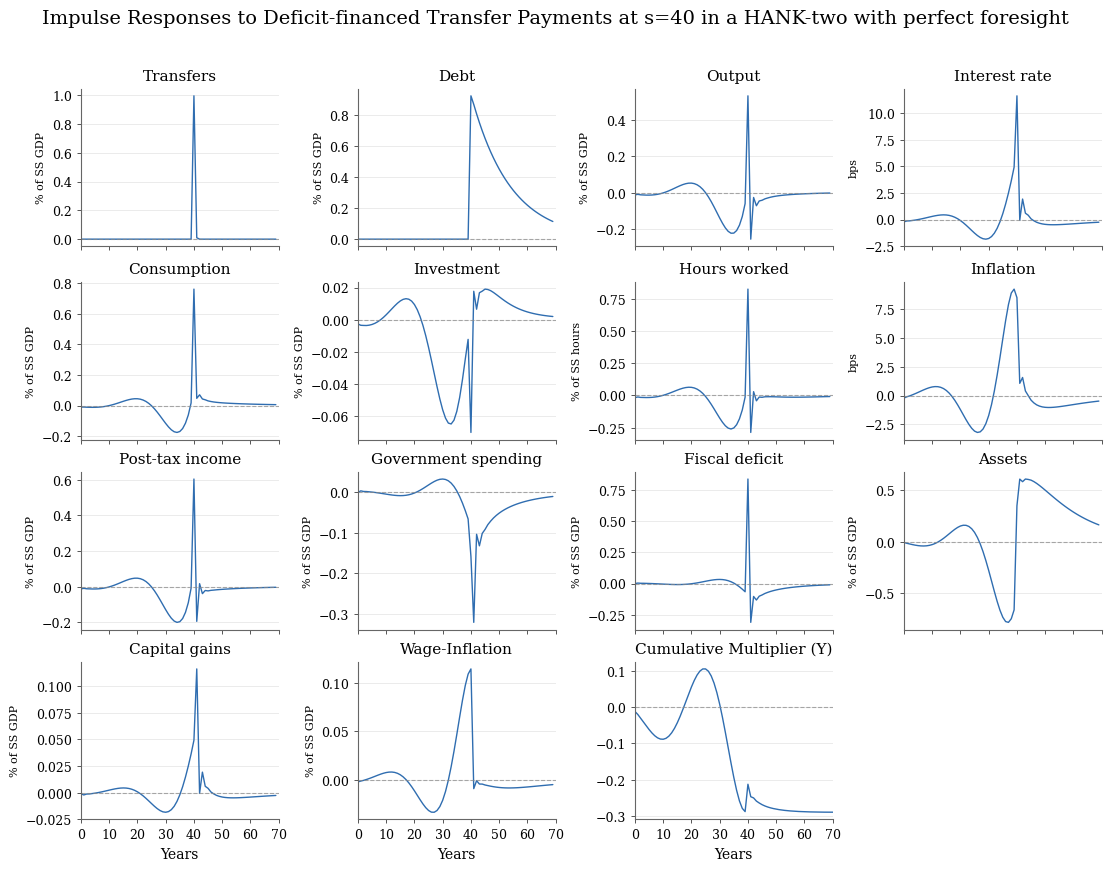

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------

horizon = 70

variables = list(dpi.keys())   # ['T', 'B', 'Y', 'r', 'C', 'I', 'N', 'pi', 'Z', 'rpost', 'G', 'deficit', 'A']

rates = {'r', 'pi'}

def rescale(var, path):
    if var in rates: return 1e4 * path                 # basis points
    if var == 'N':   return 100 * path / ss_mt['N']       # % of steady-state hours
    return 100 * path / ss_mt['Y']                        # % of steady-state GDP

units = {v: 'bps' if v in rates else ('% of SS hours' if v == 'N' else '% of SS GDP')
         for v in variables}

irf_color = "#2F6DB0"       # muted blue
zero_color = "#888888"

plt.rcParams.update({
    "savefig.directory": 'C:/Users/herr-/Documents/Master ECO/Thesis/Results',
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------

ncols = 4
nrows = 4

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(11, 8),
    sharex=True,
    constrained_layout=True
)

axes = np.asarray(axes).flatten()

# ---------------------------------------------------------
# Plot IRFs
# ---------------------------------------------------------

titles = {
    "Tr": "Transfers",
    "B": "Debt",
    "Y": "Output",
    "r": "Interest rate",
    "C": "Consumption",
    "I": "Investment",
    "N": "Hours worked",
    "rpost" : "Capital gains",
    "pi": "Inflation",
    "piw" : "Wage-Inflation", 
    "Z": "Post-tax income",
    "G": "Government spending",
    "deficit": "Fiscal deficit",
    "A": "Assets",
    "mult_paths": "Cumulative Multiplier (Y)",

}

for i, var in enumerate(variables):

    ax = axes[i]

    # IRF
    ax.plot(
        rescale(var, dpi[var])[:horizon],
        color=irf_color,
        linewidth=1,
        solid_capstyle="round"
    )

    # Zero line
    ax.axhline(
        0,
        color=zero_color,
        linewidth=0.8,
        linestyle="--",
        alpha=0.7
    )

    # Title
    ax.set_title(
        var,
        fontsize=11,
        fontweight="medium",
        pad=6
    )

    # X-axis
    ax.set_xlim(0, horizon - 1)
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70])
    ax.set_ylabel(units[var], fontsize=8)
    # Light horizontal grid
    ax.grid(
        axis="y",
        color="#D9D9D9",
        linewidth=0.6,
        alpha=0.6
    )

    # Ticks
    ax.tick_params(
        length=3,
        width=0.7,
        color="#555555"
    )

    # Slightly lighter spines
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.set_title(titles[var])


##########################
#cumulative multiplier
ax = axes[len(variables)]
ax.plot(
        mult_paths,
        color=irf_color,
        linewidth=1,
        solid_capstyle="round",
        label=fr"$\rho_B = {rhoB}$"
    )
ax.axhline(0, color=zero_color, linewidth=0.8, linestyle="--", alpha=0.7)
ax.set_xlim(0, horizon - 10)
ax.set_xticks([0, 10, 20, 30, 40, 50,60,70])
ax.grid(axis="y", color="#D9D9D9", linewidth=0.6, alpha=0.6)
ax.tick_params(length=3, width=0.7, color="#555555")
ax.spines["left"].set_color("#666666")
ax.spines["bottom"].set_color("#666666")
ax.set_title(titles["mult_paths"])

# ---------------------------------------------------------
# Remove unused panels
# ---------------------------------------------------------

for ax in axes[len(variables)+1:]:
    ax.remove()


# ---------------------------------------------------------
# X-axis labels
# ---------------------------------------------------------

# Only label the bottom row to avoid repetition
for i, ax in enumerate(axes[:len(variables)+1]):

    if i // ncols == nrows - 1:
        ax.set_xlabel("Years", labelpad=4)
    else:
        ax.tick_params(labelbottom=False)


# ---------------------------------------------------------
# Figure title
# ---------------------------------------------------------

fig.suptitle(
    "Impulse Responses to Deficit-financed Transfer Payments at s=40 in a HANK-two with perfect foresight", 
    fontsize=14,
    fontweight="medium",
    y=1.07
)
#"Impulse Responses to Tax and Deficit Shocks in a high-liquidity HANK-one",
plt.show()

In [28]:
fig.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/no MIT HANK-two.png",
    bbox_inches="tight"
)

# Multiple thetas


In [24]:
theta_cds = [0.0, 0.3, 0.7, 1.0]

dpis = {}
for theta_cd in theta_cds:
    E = E_cog_disc(theta_cd, T)

    Js_cache_beh = {}
    Js_cache_beh['HA-mt'] = dict(Js_cache_mt)          # keep accounting sub-blocks untouched
    het_name = find_het_block_name(hh_all['HA-mt'])
    J_het = Js_cache_mt[het_name]

    beh = {o: {i: manipulate_separable(np.asarray(J_het[o, i]), E)
                for i in J_het.inputs}
            for o in J_het.outputs}
    Js_cache_beh['HA-mt'][het_name] = sj.JacobianDict(beh, outputs=J_het.outputs, inputs=J_het.inputs, T=T)

    Gs_beh = models_all['HA-mt'].solve_jacobian(ss_all['HA-mt'], unknowns, targets, inputs, outputs,
                                           T=T, Js=Js_cache_beh['HA-mt'])
    dpis[theta_cd] = Gs_beh @ shock


def multiplier_path(dY, dG, r):
    q = (1 + r) ** (-np.arange(len(dY)))
    cum_dY = np.cumsum(q * dY)
    cum_dG = np.cumsum(q * dG)
    return cum_dY / cum_dG

mult_paths = {theta_cd: multiplier_path(dpis[theta_cd]['Y'], dT, calib['r']) for theta_cd in theta_cds}

### old one for hank two and so on


In [50]:

theta_cds = [0.0, 0.3, 0.7, 1.0]

dpis = {}
for theta_cd in theta_cds:
    E = E_cog_disc(theta_cd, T)

    Js_cache_beh = {}
    for m in models_all:
        Js_cache_beh[m] = dict(Js_cache[m])          # accounting sub-blocks untouched
        het_name = find_het_block_name(hh_all[m])
        J_het = Js_cache[m][het_name]

        beh = {o: {i: manipulate_separable(np.asarray(J_het[o, i]), E)
                   for i in J_het.inputs}
               for o in J_het.outputs}
        Js_cache_beh[m][het_name] = sj.JacobianDict(beh, outputs=J_het.outputs, inputs=J_het.inputs, T=T)

    Gs_beh = {m: models_all[m].solve_jacobian(ss_all[m], unknowns, targets, inputs, outputs,
                                               T=T, Js=Js_cache_beh[m])
              for m in models_all}

    dpis[theta_cd] = Gs_beh['HA-two'] @ shock

NameError: name 'Js_cache' is not defined

# Plotting multiple thetas

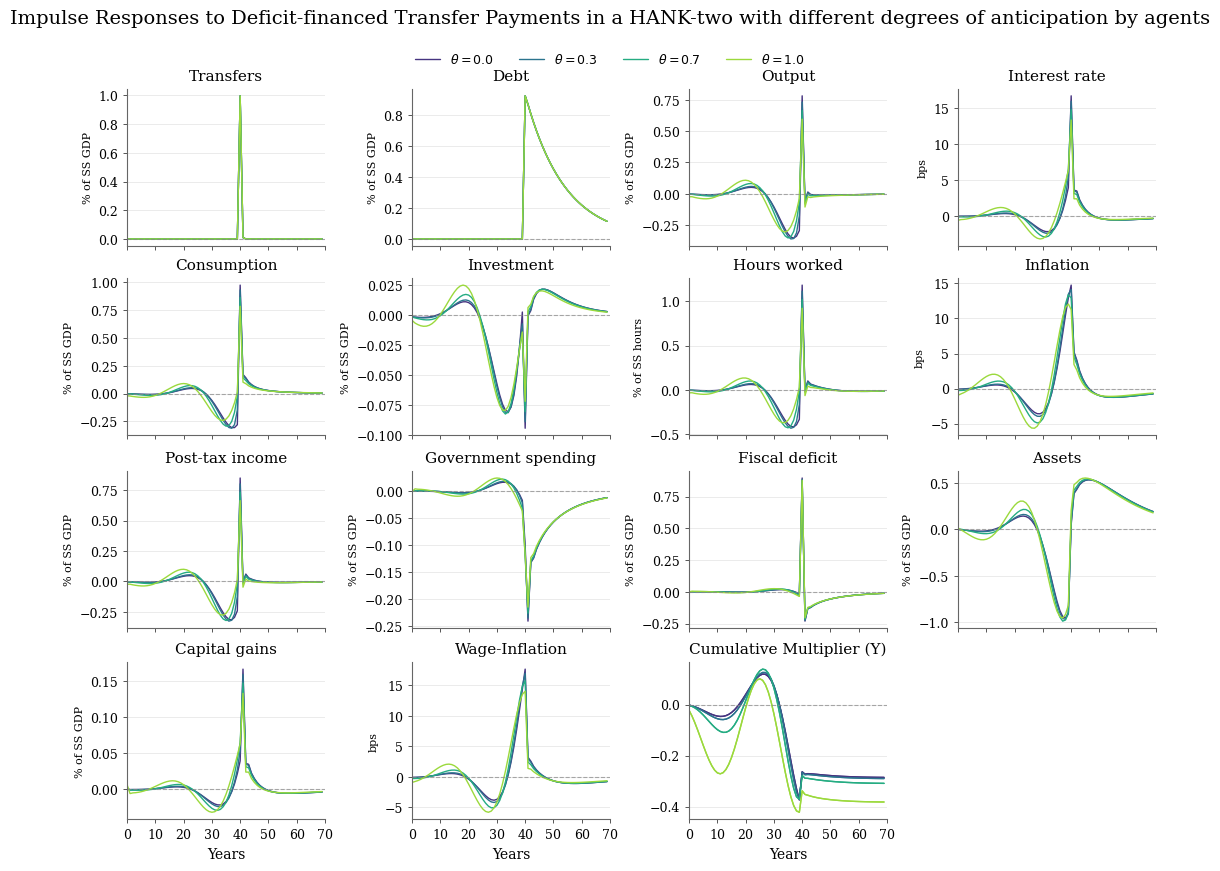

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Settings
# ---------------------------------------------------------

horizon = 70

variables = list(next(iter(dpis.values())).keys())   # ['T', 'B', 'Y', 'r', 'C', 'I', 'N', 'pi', 'Z', 'rpost', 'G', 'deficit', 'A']


rates = {'r', 'pi', 'piw'}

def rescale(var, path):
    if var in rates: return 1e4 * path                 # basis points
    if var == 'N':   return 100 * path / ss_mt['N']       # % of steady-state hours
    return 100 * path / ss_mt['Y']                        # % of steady-state GDP

units = {v: 'bps' if v in rates else ('% of SS hours' if v == 'N' else '% of SS GDP')
         for v in variables}

# Publication-style colors
irf_color = "#2F6DB0"       # muted blue
zero_color = "#888888"
# Global matplotlib style
plt.rcParams.update({
    "savefig.directory": 'C:/Users/herr-/Documents/Master ECO/Thesis/Results',
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
})

# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------

ncols = 4
nrows = 4

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(11, 8),
    sharex=True,
    constrained_layout=True
)

axes = np.asarray(axes).flatten()

# ---------------------------------------------------------
# Plot IRFs
# ---------------------------------------------------------

titles = {
    "Tr": "Transfers",
    "B": "Debt",
    "Y": "Output",
    "r": "Interest rate",
    "C": "Consumption",
    "I": "Investment",
    "N": "Hours worked",
    "rpost" : "Capital gains",
    "pi": "Inflation",
    "piw" : "Wage-Inflation",
    "Z": "Post-tax income",
    "G": "Government spending",
    "deficit": "Fiscal deficit",
    "A": "Assets",    
    "mult_paths": "Cumulative Multiplier (Y)",
}

cmap = plt.cm.viridis
colors = cmap(np.linspace(0.15, 0.85, len(theta_cds)))

for i, var in enumerate(variables):
    ax = axes[i]
    for theta_cd, color in zip(theta_cds, colors):
        ax.plot(
            rescale(var, dpis[theta_cd][var])[:horizon],
            color=color,
            linewidth=1,
            solid_capstyle="round",
            label=fr"$\theta = {theta_cd}$"
        )
    ax.axhline(0, color=zero_color, linewidth=0.8, linestyle="--", alpha=0.7)
    ax.set_xlim(0, horizon - 10)
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70])
    ax.set_ylabel(units[var], fontsize=8)
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.6, alpha=0.6)
    ax.tick_params(length=3, width=0.7, color="#555555")
    ax.spines["left"].set_color("#666666")
    ax.spines["bottom"].set_color("#666666")
    ax.set_title(titles[var])

##########################
#cumulative multiplier, problem
ax = axes[len(variables)]
for theta_cd, color in zip(theta_cds, colors):
    ax.plot(
        mult_paths[theta_cd][:horizon], 
        color=color, linewidth=1,
        solid_capstyle="round", 
        label=fr"$\theta = {theta_cd}$"
    )
for theta_cd, color in zip(theta_cds, colors):
    ax.plot(
        mult_paths[theta_cd][:horizon],
        color=color,
        linewidth=1,
        solid_capstyle="round",
        label=fr"$\theta_cd = {theta_cd}$"
    )
#no problem    
ax.axhline(0, color=zero_color, linewidth=0.8, linestyle="--", alpha=0.7)
ax.set_xlim(0, horizon - 10)
ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70])
ax.grid(axis="y", color="#D9D9D9", linewidth=0.6, alpha=0.6)
ax.tick_params(length=3, width=0.7, color="#555555")
ax.spines["left"].set_color("#666666")
ax.spines["bottom"].set_color("#666666")
ax.set_title(titles["mult_paths"])

# ---------------------------------------------------------
# Remove unused panels
# ---------------------------------------------------------

for ax in axes[len(variables)+1:]:
    ax.remove()


# ---------------------------------------------------------
# X-axis labels
# ---------------------------------------------------------

# Only label the bottom row to avoid repetition
for i, ax in enumerate(axes[:len(variables)+1]):

    if i // ncols == nrows - 1:
        ax.set_xlabel("Years", labelpad=4)
    else:
        ax.tick_params(labelbottom=False)


# ---------------------------------------------------------
# Figure title
# ---------------------------------------------------------

fig.suptitle(
    "Impulse Responses to Deficit-financed Transfer Payments in a HANK-two with different degrees of anticipation by agents", 
    fontsize=14,
    fontweight="medium",
    y=1.07
)
#"Impulse Responses to Tax and Deficit Shocks in a high-liquidity HANK-one",

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=len(theta_cds),
    frameon=False,
    fontsize=9
)


plt.show()

In [26]:
fig.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/cg_11_low.png",
    bbox_inches="tight"
)

## Cognitive discounting over

# GINI coefficients

In [52]:
ha=sj.combine([*other_blocks, hh_all['HA-hi-liq']])
ss=ha.steady_state({**ss_all['HA-hi-liq'], **calib })

In [47]:
#ss.internals['hh']['D'].sum(axis=1) #this sums away a (axis=0 is e)

In [48]:
#ss.internals['hh']['e_grid']

In [49]:
#ss_two.internals

In [53]:
#income data from https://ec.europa.eu/eurostat/databrowser/view/ilc_di11/default/table?lang=en
import pandas as pd
inc = pd.read_csv('C:/Users/herr-/Documents/Master ECO/Thesis/Income.csv', header=None)
da = inc[0].values[:]   # rows 0-3 are pre-periods, impcs start at 4
sd = inc[1].values[:]

In [54]:
#HFCS 21
import pandas as pd
df = pd.read_csv('C:/Users/herr-/Documents/Master ECO/Thesis/Wealth.csv', header=None)
impc_data = df[0].values[:]   # rows 0-3 are pre-periods, impcs start at 4
impc_sd = df[1].values[:]

In [55]:
from models.two_account_calvo import interpolate # To interpolate cdf
from scipy.integrate import trapz       # To calculate Gini

plt.rc('font', size=15)


# HANK ONE

In [56]:
#income
def get_lorenz(ss, percentiles):
    D = ss.internals['hh']['D'].sum(axis=1) 
    e_grid = ss.internals['hh']['e_grid']
    lorenz_model = np.array([np.interp(pctl, D.cumsum(), (e_grid * D).cumsum()) / ss['Y'] for pctl in percentiles])
    return lorenz_model

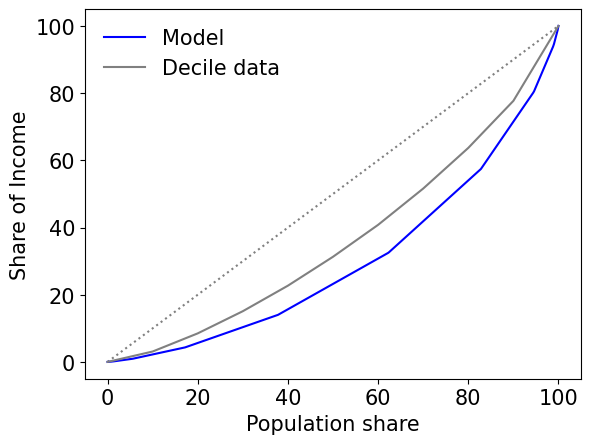

In [57]:
percentiles_detail = np.arange(501) / 500
lorenz_model_detail = get_lorenz(ss, percentiles_detail)


plt.plot([0, 100], [0, 100], linestyle='dotted', color='gray')
plt.plot(percentiles_detail*100, lorenz_model_detail*100, label='Model', color='blue')
plt.plot(da, sd, label='Decile data', color='gray')
plt.ylabel('Share of Income')
plt.xlabel('Population share')
plt.legend(frameon=False)
plt.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/Ginione_income.png",
    bbox_inches="tight"
)
plt.show()


In [58]:
print(1 - 2 * np.trapz(lorenz_model_detail, percentiles_detail))

0.3981037688686647


In [59]:
#ss.internals['hh']
def get_lorenz(ss, percentiles):
    D = ss.internals['hh']['D'].sum(axis=0) # distribution over asset grid alone
    a_grid = ss.internals['hh']['a_grid']
    lorenz_model = np.array([np.interp(pctl, D.cumsum(), (a_grid * D).cumsum()) / ss['A'] for pctl in percentiles])
    return lorenz_model

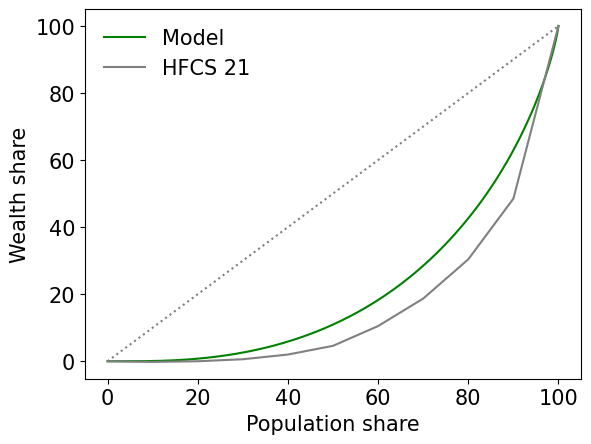

In [60]:
percentiles_detail = np.arange(501) / 500
lorenz_model_detail = get_lorenz(ss, percentiles_detail)


plt.plot([0, 100], [0, 100], linestyle='dotted', color='gray')
plt.plot(percentiles_detail*100, lorenz_model_detail*100, label='Model', color='green')
plt.plot(impc_data, impc_sd, label='HFCS 21', color='gray')
plt.ylabel('Wealth share')
plt.xlabel('Population share')
plt.legend(frameon=False)
plt.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/GInione.png",
    bbox_inches="tight"
)
plt.show()



In [61]:
print(1 - 2 * np.trapz(lorenz_model_detail, percentiles_detail))
#0.5057397899108438

0.5650184951171211


# HA-TWO

In [60]:
#ss_two.internals['twoasset_calvo']['D'].sum(axis=(0,2,3)) 

In [38]:
data = ss_mt.internals['twoasset_calvo']
D, a_grid, b_grid = data['D'], data['a_grid'], data['b_grid']


Djoint = D.sum(axis=(0,1))     # sum out Calvo state and income -> shape (50, 50) = (a, b)

D_a = Djoint.sum(axis=0)        # marginalize out liquid b -> shape (50,), distribution over illiquid a
D_b = Djoint.sum(axis=1)        # marginalize out illiquid a -> shape (50,), distribution over liquid b

In [39]:
D=ss_mt.internals['twoasset_calvo']['D']
a=ss_mt.internals['twoasset_calvo']['a_grid']
b=ss_mt.internals['twoasset_calvo']['b_grid']

In [40]:
A=np.vdot(a, D_a)+np.vdot(b, D_b)
A

4.062260951036297

In [41]:
ss_mt['A']

4.062252071592128

In [42]:
#GINI

#ss.internals['hh']
def get_lorenz(ss_mt, percentiles):
    D = ss_mt.internals['twoasset_calvo']['D'].sum(axis=0) # distribution over asset grid alone
    a_grid = ss_mt.internals['twoasset_calvo']['a_grid']
    b_grid = ss_mt.internals['twoasset_calvo']['b_grid']
    lorenz_model = np.array([np.interp(pctl, D_b.cumsum(), (b_grid * D_b).cumsum()) / ss_mt['A'] for pctl in percentiles])
    return lorenz_model

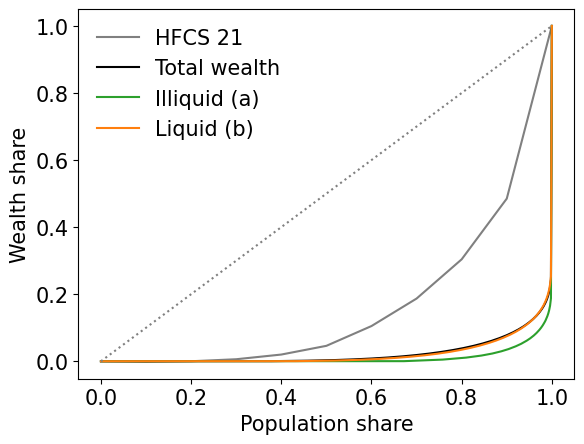

In [43]:
def lorenz_from_dist(dist, grid, percentiles):
    """Lorenz curve for a 1-D distribution `dist` over grid values `grid`."""
    order = np.argsort(grid)
    grid_sorted, dist_sorted = grid[order], dist[order]
    cum_pop = dist_sorted.cumsum()
    cum_wealth = (grid_sorted * dist_sorted).cumsum()
    cum_wealth /= cum_wealth[-1]          # normalize so the curve ends at 1
    return np.interp(percentiles, cum_pop, cum_wealth)

percentiles_detail = np.arange(501) / 500

# Individual asset Lorenz curves
lorenz_a = lorenz_from_dist(D_a, a_grid, percentiles_detail)   # illiquid (a)
lorenz_b = lorenz_from_dist(D_b, b_grid, percentiles_detail)   # liquid (b)

# Total wealth (a + b) Lorenz curve — needs the joint distribution, not the marginals
total_wealth_grid = (a_grid[:, None] + b_grid[None, :]).flatten()
joint_dist_flat = Djoint.flatten()
lorenz_total = lorenz_from_dist(joint_dist_flat, total_wealth_grid, percentiles_detail)

plt.plot(impc_data/100, impc_sd/100, label='HFCS 21', color='gray')
plt.plot(percentiles_detail, lorenz_total, label='Total wealth', color='black')
plt.plot(percentiles_detail, lorenz_a, label='Illiquid (a)', color='tab:green')
plt.plot(percentiles_detail, lorenz_b, label='Liquid (b)', color='tab:orange')
plt.plot([0, 1], [0, 1], linestyle='dotted', color='gray')
plt.ylabel('Wealth share')
plt.xlabel('Population share')
plt.legend(frameon=False)
plt.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/Ginitwo_swedish.png",
    bbox_inches="tight"
)
plt.show()

In [44]:
gini_a = 1 - 2 * np.trapz(lorenz_a, percentiles_detail)
gini_b = 1 - 2 * np.trapz(lorenz_b, percentiles_detail)
print(gini_a, gini_b)


#N_test_5: 0.9782163505102218 0.9558449266850595
#N_test_6,7: 0.9782163505102218 0.9558449266850595
#11: 0.9782163505102218 0.9558449266850595

#low wealth: 0.9655190906843021 0.9312386177323241
#lowe wealth, swedish: 0.9714101435357023 0.9731001295015042

0.9778675051706813 0.9551445195921091


In [22]:
ss_mt.internals['twoasset_calvo']['y']

array([0.03281624, 0.05285045, 0.08511547, 0.13707817, 0.22076394,
       0.35553957, 0.57259528, 0.92216277, 1.48514003, 2.39181301,
       3.85200678])

In [35]:
#GINI

#ss.internals['hh']
def get_lorenz(ss_mt, percentiles):
    D = ss_mt.internals['twoasset_calvo']['D'].sum(axis=(0,2,3)) # distribution over asset grid alone
    y = ss_mt.internals['twoasset_calvo']['y']
    lorenz_model = np.array([np.interp(pctl, D.cumsum(), (y * D).cumsum()) / ss_mt['Z'] for pctl in percentiles])
    return lorenz_model

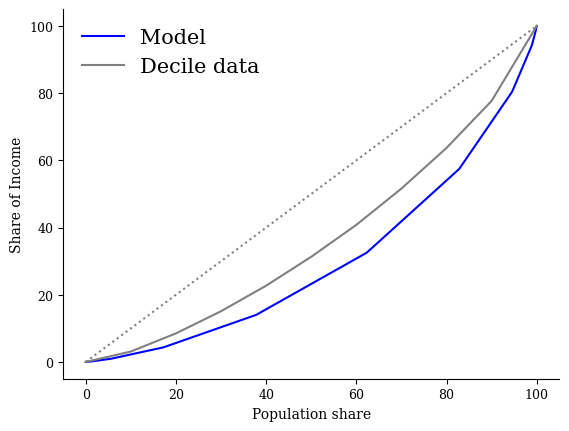

In [36]:
percentiles_detail = np.arange(501) / 500
lorenz_model_detail = get_lorenz(ss_mt, percentiles_detail)


plt.plot([0, 100], [0, 100], linestyle='dotted', color='gray')
plt.plot(percentiles_detail*100, lorenz_model_detail*100, label='Model', color='blue')
plt.plot(da, sd, label='Decile data', color='gray')
plt.ylabel('Share of Income')
plt.xlabel('Population share')
plt.legend(frameon=False)
plt.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/GIni_income_swedish.png",
    bbox_inches="tight"
)
plt.show()


In [37]:
print(1 - 2 * np.trapz(lorenz_model_detail, percentiles_detail))
#11: 0.39810376886792265 both on low and high wealth
#swedish persistance: 0.2902725428782402

0.39810376886839083


### Individual cumulative distributions, which I did not include in the paper as they are already covered by the distributions above

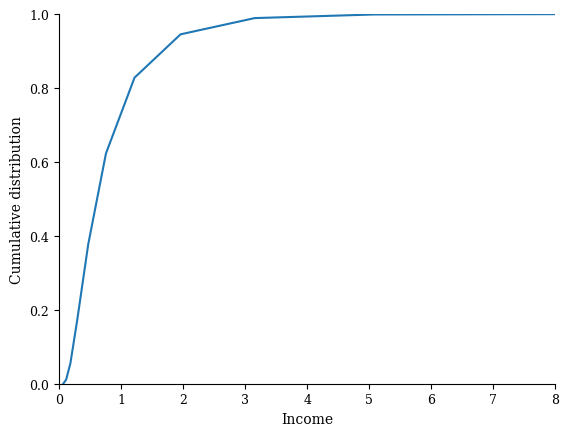

In [114]:
D = ss.internals['hh']['D'].sum(axis=1)
e_grid = ss.internals['hh']['e_grid']
plt.plot(e_grid, np.cumsum(pi_e))
plt.ylim([0, 1])
plt.xlim([0, 8]) #11 prod states
plt.xlabel('Income')
plt.ylabel('Cumulative distribution')
plt.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/cdf income_one.png",
    bbox_inches="tight"
)


#8.17 is the highest income and most of the population is below or around 1. 

In [53]:
def get_lorenz(ss, percentiles):
    D = ss['D'].sum(axis=0) # distribution over asset grid alone
    a_grid = ss['a_grid']
    lorenz_model = np.array([np.interp(pctl, D.cumsum(), (a_grid * D).cumsum()) / ss['A'] for pctl in percentiles])
    return lorenz_model

In [ ]:
D, a_grid, b_grid = ss_mt.internals['twoasset_calvo']['D'], ss_mt.internals['twoasset_calvo']['a_grid'], ss_mt.internals['twoasset_calvo']['b_grid']

Djoint = D.sum(axis=(0, 1))     # sum out Calvo state and income -> shape (50, 50) = (a, b)

D_a = Djoint.sum(axis=1)        # marginalize out liquid b -> shape (50,), distribution over illiquid a
D_b = Djoint.sum(axis=0)        # marginalize out illiquid a -> shape (50,), distribution over liquid b

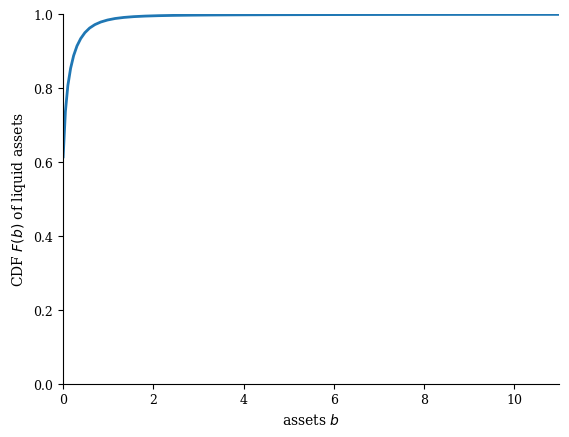

In [52]:
#displayed already by gini
cdf_b = D_b.cumsum()

plt.plot(b_grid, cdf_b, linewidth=2)
plt.ylim([0, 1])
plt.xlim([0, 11])
plt.xlabel(r'assets $b$')
plt.ylabel(r'CDF $F(b)$ of liquid assets')
plt.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/cdf liquid.png",
    bbox_inches="tight"
)
plt.show()

# DAG

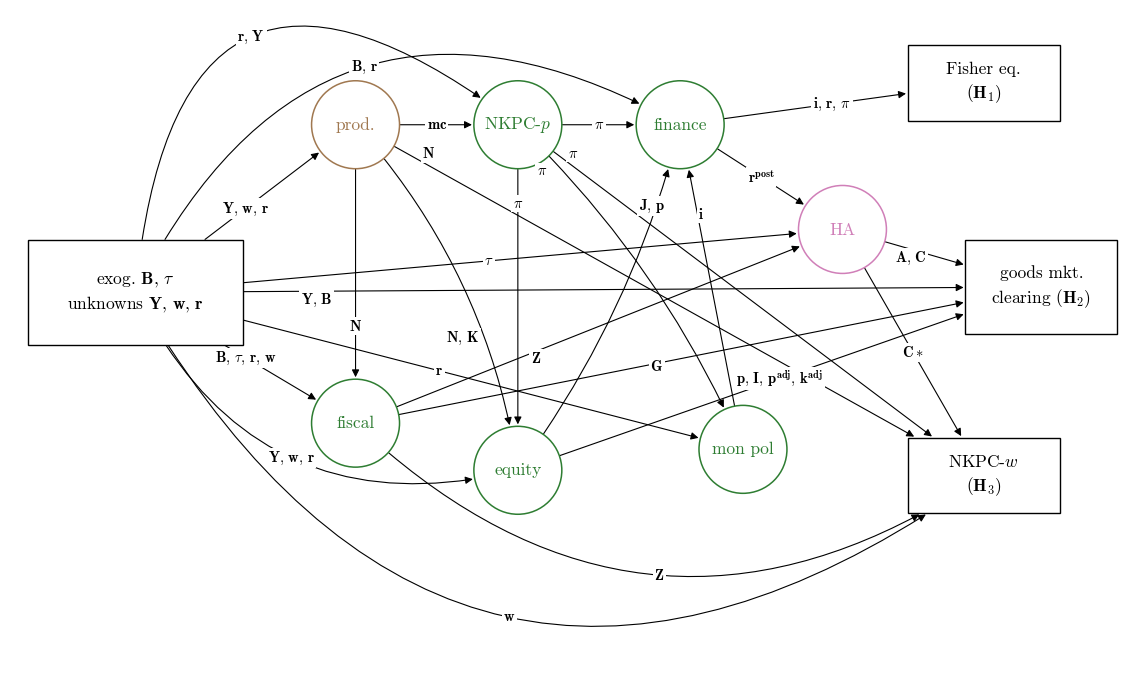

In [82]:
"""
DAG of the means-tested two-asset HANK model, drawn in the style of
Auclert, Bardoczy, Rognlie, Straub (2021)

Block mapping (paper name <- code in the ikc replication):
  prod.     <- labor, investment         (inside labor_to_investment_..._combined [0])
  NKPC-p    <- pricing_solved            (inside [0])
  equity    <- dividend, val_firm_solved (inside [0])
  mon pol   <- taylor [2]
  finance   <- share_bond [1] + finance [3]
  fiscal    <- fiscalrule_mt [5]
  HA        <- Two Asset Model_mt [6]
  H1        <- target 'fisher'   (computed in finance)
  H2        <- target 'goods_mkt' (mkt_clearing [7])
  H3        <- target 'wnkpc'    (wage_inflation [4] + union [8])
Variable mapping: Tr -> tau, J_end_period -> p, UCE -> U, rpost -> r^post.
"""
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch

plt.rcParams.update({
    "font.family": "cmr10",
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
})

GREEN, BROWN, PINK = "#2E7D32", "#A07850", "#D07FB8"

# ------------------------------------------------------------------ nodes
# 'c' circle or 'b' box (radius or w, h)
nodes = {
    "EX":    dict(kind="b", xy=(1.35, 2.55), size=(2.05, 1.0), color="black",
                  text=r"exog. $\mathbf{B},\,\tau$" + "\n" + r"unknowns $\mathbf{Y},\,\mathbf{w},\,\mathbf{r}$"),
    "PROD":  dict(kind="c", xy=(3.45, 4.15), size=0.42, color=BROWN, text="prod."),
    "NKPCP": dict(kind="c", xy=(5.00, 4.15), size=0.42, color=GREEN, text=r"NKPC-$p$"),
    "FIN":   dict(kind="c", xy=(6.55, 4.15), size=0.42, color=GREEN, text="finance"),
    "HA":    dict(kind="c", xy=(8.10, 3.15), size=0.42, color=PINK, text="HA"),
    "MP":    dict(kind="c", xy=(7.15, 1.05), size=0.42, color=GREEN, text="mon pol"),
    "FISC":  dict(kind="c", xy=(3.45, 1.30), size=0.42, color=GREEN, text="fiscal"),
    "EQ":    dict(kind="c", xy=(5.00, 0.85), size=0.42, color=GREEN, text="equity"),
    "H1":    dict(kind="b", xy=(9.45, 4.55), size=(1.45, 0.72), color="black",
                  text="Fisher eq.\n" + r"$\mathbf{(H_1)}$"),
    "H2":    dict(kind="b", xy=(10, 2.60), size=(1.45, 0.90), color="black",
                  text="goods mkt.\nclearing " + r"$\mathbf{(H_2)}$"),
    "H3":    dict(kind="b", xy=(9.45, 0.80), size=(1.45, 0.72), color="black",
                  text=r"NKPC-$w$" + "\n" + r"$\mathbf{(H_3)}$"),
}

# --------------------------------------------------------------- label text
SPECIAL = {
    "pi":   r"\pi",
    "tau":  r"\tau",
    "rpost": r"\mathbf{r}^{\mathbf{post}}",
    "padj": r"\mathbf{p}^{\mathbf{adj}}",
    "kadj": r"\mathbf{k}^{\mathbf{adj}}",
}
def L(*names):
    parts = [SPECIAL.get(n, r"\mathbf{%s}" % n) for n in names]
    return "$" + r",\,".join(parts) + "$"

# ------------------------------------------------------------------- edges
# (src, dst, labels, rad, t, (dx, dy), start_anchor, end_anchor)
E = [
    ("EX", "PROD",  L("Y", "w", "r"),                 0.00, 0.50, (0, 0)),
    ("EX", "NKPCP", L("r", "Y"),                      -0.90, 0.50, (0, 0)),
    ("EX", "FIN",   L("B", "r"),                      -0.52, 0.50, (0, 0)),
    ("EX", "H3",    L("w"),                            0.55, 0.50, (0, 0)),
    ("EX", "EQ",    L("Y", "w", "r"),                  0.40, 0.50, (0, 0)),
    ("EX", "FISC",  L("B", "tau", "r", "w"),           0.00, 0.50, (0, 0)),
    ("EX", "MP",    L("r"),                            0.00, 0.50, (0, 0)),
    ("EX", "HA",    L("tau"),                          0.00, 0.50, (0, 0)),
    ("EX", "H2",    L("Y", "B"),                       0.00, 0.50, (-2.6, -0.1)),
    

    ("PROD", "NKPCP", L("mc"),                         0.00, 0.50, (0, 0)),
    ("PROD", "FISC",  L("N"),                          0.00, 0.50, (0, -0.5)),
    ("PROD", "EQ",    L("N", "K"),                    -0.15, 0.50, (0, -0.5)),
    ("PROD", "H3",    L("N"),                          0.00, 0.50, (-2.3, 1.4)),

    ("NKPCP", "FIN", L("pi"),                          0.00, 0.50, (0, 0)),
    ("NKPCP", "EQ",  L("pi"),                          0.00, 0.50, (0, 0.9)),
    ("NKPCP", "MP",  L("pi"),                          -0.10, 0.50, (-1, 1)),
    ("NKPCP", "H3",  L("pi"),                          0.00, 0.50, (-1.7, 1.4)),

    ("EQ", "FIN", L("J", "p"),                         0.10, 0.50, (0.34, 0.95)),
    ("EQ", "H2",  L("p", "I", "padj", "kadj"),         0.00, 0.50, (0, 0)),
    ("MP", "FIN", L("i"),                              0.00, 0.50, (-0.1, 0.7)),
    ("FIN", "HA", L("rpost"),                          0.00, 0.50, (0, 0)),
    ("FIN", "H1", L("i", "r", "pi"),                   0.00, 0.50, (0, 0)),

    ("FISC", "HA", L("Z"),                             0.00, 0.50, (-0.6, -0.3)),
    ("FISC", "H3", L("Z"),                             0.4, 0.50, (0, 0)),
    ("FISC", "H2", L("G"),                             0.00, 0.50, (-0.4, -0.1)),
    ("HA", "H2",   L("A", "C"),                        0.00, 0.50, (-0.3, 0)),
    ("HA", "H3",   L("C*"),                             0.00, 0.50, (0, 0)),
]

# --------------------------------------------------------------------- draw
def draw(path_png=None, path_pdf=None, figsize=(13.2, 6.6)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0.15, 10.8)
    ax.set_ylim(-1, 5.25)
    ax.set_aspect("equal")
    ax.axis("off")

    patches = {}
    for k, n in nodes.items():
        x, y = n["xy"]
        if n["kind"] == "c":
            p = Circle((x, y), n["size"], fc="white", ec=n["color"], lw=1.1, zorder=2)
            ax.add_patch(p)
            ax.text(x, y, n["text"], color=n["color"], ha="center", va="center",
                    fontsize=12.5, zorder=3)
        else:
            w, h = n["size"]
            p = Rectangle((x - w / 2, y - h / 2), w, h, fc="white", ec="black", lw=1.0, zorder=2)
            ax.add_patch(p)
            ax.text(x, y, n["text"], color="black", ha="center", va="center",
                    fontsize=12.5, zorder=3, linespacing=1.35)
        patches[k] = p

    for (s, d, lab, rad, t, off) in E:
        A = np.array(nodes[s]["xy"], float)
        B = np.array(nodes[d]["xy"], float)
        arr = FancyArrowPatch(A, B, connectionstyle=f"arc3,rad={rad}",
                              arrowstyle="-|>", mutation_scale=11, lw=0.8, color="black",
                              patchA=patches[s], patchB=patches[d],
                              shrinkA=0, shrinkB=1.0, zorder=1)
        ax.add_patch(arr)
        # label position on the quadratic Bezier A -> c -> B
        mid = (A + B) / 2
        dx, dy = B - A
        c = mid + rad * np.array([dy, -dx])
        P = (1 - t) ** 2 * A + 2 * (1 - t) * t * c + t ** 2 * B
        ax.text(P[0] + off[0], P[1] + off[1], lab, ha="center", va="center", fontsize=10.5,
                zorder=4, bbox=dict(fc="white", ec="none", pad=1.2))

    fig.tight_layout(pad=0.2)
    if path_png:
        fig.savefig(path_png, dpi=220, bbox_inches="tight", facecolor="white")
    if path_pdf:
        fig.savefig(path_pdf, bbox_inches="tight", facecolor="white")
    return fig


if __name__ == "__main__":
    out = sys.argv[1] if len(sys.argv) > 1 else "dag_hank_mt"
    draw(out + ".png", out + ".pdf")

plt.savefig(
    "C:/Users/herr-/Documents/Master ECO/Thesis/Results/DAG_new.png",
    bbox_inches="tight"
)
plt.show()